# IEEE-CIS Fraud Detection: Baseline Models
## DSCI 598 Capstone, Week 3
### Ben Miller

Companion notebook: `bm-fraud-detection-exploratory` (exploratory analysis and technical challenges).

# Part 3: Baseline models and a first submission
> Begin building and evaluating models. Start by building relatively simple baseline models. You do not have to include all available features in your model if doing so presents technical challenges. Your team should submit at least one model to the competition this week.

### Imports, seeds and constants

In [1]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Kaggle mounts the competition files here (read-only)
DATA_DIR = '/kaggle/input/competitions/ieee-fraud-detection'

# Column names used throughout
ID_COLUMN = 'TransactionID'
TARGET = 'isFraud'
TIME_COLUMN = 'TransactionDT'      # seconds from an undisclosed starting point, not a real timestamp
AMOUNT_COLUMN = 'TransactionAmt'

SECONDS_PER_DAY = 24 * 60 * 60

SUBMISSION_PATH = 'submission.csv'   # Kaggle offers files in /kaggle/working (the default folder) for submission

# Validation
VALIDATION_FRACTION = 0.2   # the most recent 20% of training transactions are held out

# Baseline 1: logistic regression on a few numeric columns
LOGREG_FEATURES = [AMOUNT_COLUMN] + [f'C{number}' for number in range(1, 15)] + ['D1', 'has_identity']
LOGREG_MAX_ITER = 1000

# Baseline 2: LightGBM on every column
MAX_BOOSTING_ROUNDS = 2000      # upper limit; early stopping picks the real number
EARLY_STOPPING_ROUNDS = 100     # stop when validation AUC hasn't improved for this many rounds
LEARNING_RATE = 0.05
NUM_LEAVES = 128
SUBSAMPLE = 0.8                 # share of rows each tree sees
COLSAMPLE_BYTREE = 0.5          # share of columns each tree sees; helps with the redundant V columns
LOG_EVERY_N_ROUNDS = 100
TOP_N_IMPORTANCES = 20

sns.set_theme(style='whitegrid')

### Data-loading functions

The same loading functions as the EDA notebook: downcast numbers, fix test's `id-01` column names, left-join identity, and flag which transactions had identity data.

In [2]:
def downcast_numeric_columns(frame):
    """
    Shrink float64 columns to float32 and integer columns to the smallest type that fits.
    The raw tables need several GB as float64; float32 roughly halves that, and tree
    models don't need the extra precision.
    """
    smaller_types = {}
    for column in frame.columns:
        if pd.api.types.is_float_dtype(frame[column]):
            smaller_types[column] = 'float32'
        elif pd.api.types.is_integer_dtype(frame[column]):
            smallest_fit = pd.to_numeric(frame[column], downcast='integer')
            smaller_types[column] = smallest_fit.dtype

    # one astype call for every column; assigning hundreds of columns one at a time fragments the DataFrame
    return frame.astype(smaller_types)


def standardize_identity_columns(identity):
    """
    Rename test_identity's 'id-01' style columns to train's 'id_01' spelling.
    The competition files use a hyphen in test and an underscore in train, so without
    this every identity feature would silently be missing in test after the merge.
    """
    renamed_columns = {}
    for column in identity.columns:
        if column.startswith('id-'):
            renamed_columns[column] = column.replace('id-', 'id_')
    return identity.rename(columns=renamed_columns)


def load_table(file_name):
    """One competition CSV, with its numeric columns downcast."""
    frame = pd.read_csv(os.path.join(DATA_DIR, file_name))
    return downcast_numeric_columns(frame)


def merge_identity(transactions, identity):
    """
    Left-join identity onto transactions by TransactionID, and flag which rows had a match.
    Only some transactions have identity data, so a left join keeps every transaction and
    leaves the identity columns missing for the rest.
    """
    # mark identity rows before the merge; transactions without a match end up missing, then 0
    flagged_identity = identity.assign(has_identity=1)
    merged = transactions.merge(flagged_identity, on=ID_COLUMN, how='left')
    merged['has_identity'] = merged['has_identity'].fillna(0).astype('int8')
    return merged


def load_split(split_name):
    """The merged transaction + identity table for 'train' or 'test'."""
    transactions = load_table(f'{split_name}_transaction.csv')
    identity = standardize_identity_columns(load_table(f'{split_name}_identity.csv'))
    return merge_identity(transactions, identity)


def memory_mb(frame):
    """How much memory a DataFrame uses, in megabytes."""
    return frame.memory_usage(deep=True).sum() / 1024 ** 2

### Load and merge train and test

In [3]:
train = load_split('train')
test = load_split('test')

print(f'train: {train.shape[0]:,} rows x {train.shape[1]} columns, {memory_mb(train):,.0f} MB')
print(f'test:  {test.shape[0]:,} rows x {test.shape[1]} columns, {memory_mb(test):,.0f} MB')

# test has no isFraud column, so every other column should match train's
missing_from_test = set(train.columns) - set(test.columns) - {TARGET}
print('columns in train but not test:', sorted(missing_from_test) if missing_from_test else 'none')

train: 590,540 rows x 435 columns, 1,604 MB
test:  506,691 rows x 434 columns, 1,387 MB
columns in train but not test: none


### Encode text columns as integers

LightGBM needs numbers. One shared code table is built from train and test together, so the same value gets the same code in both files.

In [4]:
def find_text_columns(frame):
    """Columns that hold strings instead of numbers (pandas 2 calls them 'object', pandas 3 'str')."""
    text_columns = []
    for column in frame.columns:
        if not pd.api.types.is_numeric_dtype(frame[column]):
            text_columns.append(column)
    return text_columns


def encode_text_columns(train, test, columns):
    """
    Replace each text column with integer codes from one table shared by train and test.
    Missing values become -1. Tree models only need the codes to be consistent, not meaningful.
    """
    for column in columns:
        combined = pd.concat([train[column], test[column]]).astype('object')
        codes, _ = pd.factorize(combined)  # factorize gives missing values the code -1
        train[column] = codes[:len(train)].astype('int32')
        test[column] = codes[len(train):].astype('int32')
    return train, test


text_columns = find_text_columns(test)
train, test = encode_text_columns(train, test, text_columns)
print(f'encoded {len(text_columns)} text columns, e.g. {text_columns[:6]}')

encoded 31 text columns, e.g. ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1']


### Time-based validation split

Test comes after train in time (see the EDA notebook), so validation uses the most recent training transactions. A random split would let the model learn from transactions that happen after the ones it's scored on.

In [5]:
def split_by_time(frame, validation_fraction):
    """Earlier transactions for training and the most recent validation_fraction for validation."""
    ordered = frame.sort_values(TIME_COLUMN)
    split_index = int(len(ordered) * (1 - validation_fraction))
    return ordered.iloc[:split_index], ordered.iloc[split_index:]


def model_feature_columns(frame):
    """
    Every column except the ID, the target and the raw time.
    Raw TransactionDT is left out because test's values are all later than train's,
    so a model that splits on it would be extrapolating.
    """
    excluded = {ID_COLUMN, TARGET, TIME_COLUMN}
    features = []
    for column in frame.columns:
        if column not in excluded:
            features.append(column)
    return features


training_part, validation_part = split_by_time(train, VALIDATION_FRACTION)
feature_columns = model_feature_columns(test)

print(f'training part:   {len(training_part):,} rows, fraud rate {training_part[TARGET].mean():.2%}')
print(f'validation part: {len(validation_part):,} rows, fraud rate {validation_part[TARGET].mean():.2%}')
print(f'{len(feature_columns)} feature columns')

training part:   472,432 rows, fraud rate 3.51%
validation part: 118,108 rows, fraud rate 3.44%
432 feature columns


### Evaluation function

The competition is scored on ROC AUC: the chance that a random fraud transaction gets a higher score than a random legitimate one. 0.5 is a coin flip and 1.0 is perfect.

In [6]:
def validation_auc(model, features, validation_part):
    """ROC AUC of the model's fraud probabilities on the validation part."""
    fraud_probabilities = model.predict_proba(validation_part[features])[:, 1]
    return roc_auc_score(validation_part[TARGET], fraud_probabilities)

### Baseline 1: logistic regression on a few numeric columns

The simplest reasonable model, as a floor: amount, the C counts, `D1` and the identity flag. Missing values are filled with the column median and features are standardized, since logistic regression handles neither missing values nor wildly different scales.

In [7]:
def build_logistic_regression():
    """Median imputation, then scaling, then logistic regression."""
    return make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(max_iter=LOGREG_MAX_ITER),
    )


logreg_model = build_logistic_regression()
logreg_model.fit(training_part[LOGREG_FEATURES], training_part[TARGET])
logreg_auc = validation_auc(logreg_model, LOGREG_FEATURES, validation_part)
print(f'logistic regression ({len(LOGREG_FEATURES)} features) validation AUC: {logreg_auc:.4f}')

logistic regression (17 features) validation AUC: 0.7787


### Baseline 2: LightGBM on every column

Gradient-boosted trees handle missing values and unscaled features on their own, so this uses every column. Early stopping on validation AUC picks the number of trees.

In [8]:
def build_lightgbm(n_estimators):
    """A LightGBM classifier with the notebook's settings and the given number of trees."""
    return lgb.LGBMClassifier(
        n_estimators=n_estimators,
        learning_rate=LEARNING_RATE,
        num_leaves=NUM_LEAVES,
        subsample=SUBSAMPLE,
        subsample_freq=1,          # subsample only takes effect when this is 1 or more
        colsample_bytree=COLSAMPLE_BYTREE,
        metric='auc',              # early stopping watches AUC, not the default log loss
        random_state=SEED,
        n_jobs=-1,
        verbose=-1,
    )


def fit_lightgbm_with_early_stopping(training_part, validation_part, features):
    """Train until validation AUC stops improving, keeping the best number of trees."""
    model = build_lightgbm(MAX_BOOSTING_ROUNDS)
    model.fit(
        training_part[features],
        training_part[TARGET],
        eval_set=[(validation_part[features], validation_part[TARGET])],
        callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS), lgb.log_evaluation(LOG_EVERY_N_ROUNDS)],
    )
    return model


lgbm_model = fit_lightgbm_with_early_stopping(training_part, validation_part, feature_columns)
lgbm_auc = validation_auc(lgbm_model, feature_columns, validation_part)
best_rounds = lgbm_model.best_iteration_
print(f'LightGBM ({len(feature_columns)} features) validation AUC: {lgbm_auc:.4f} at {best_rounds} trees')

Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.913667
[200]	valid_0's auc: 0.921361
[300]	valid_0's auc: 0.922125
Early stopping, best iteration is:
[277]	valid_0's auc: 0.922659
LightGBM (432 features) validation AUC: 0.9227 at 277 trees


### Compare the baselines

In [9]:
baseline_results = pd.DataFrame({
    'model': ['logistic regression', 'LightGBM'],
    'features': [len(LOGREG_FEATURES), len(feature_columns)],
    'validation_auc': [logreg_auc, lgbm_auc],
})
print(baseline_results.round(4).to_string(index=False))

              model  features  validation_auc
logistic regression        17          0.7787
           LightGBM       432          0.9227


### Feature importance

Which columns LightGBM's splits gained the most from. Gain is the total improvement a column's splits produced, which is more informative than how many times it was used.

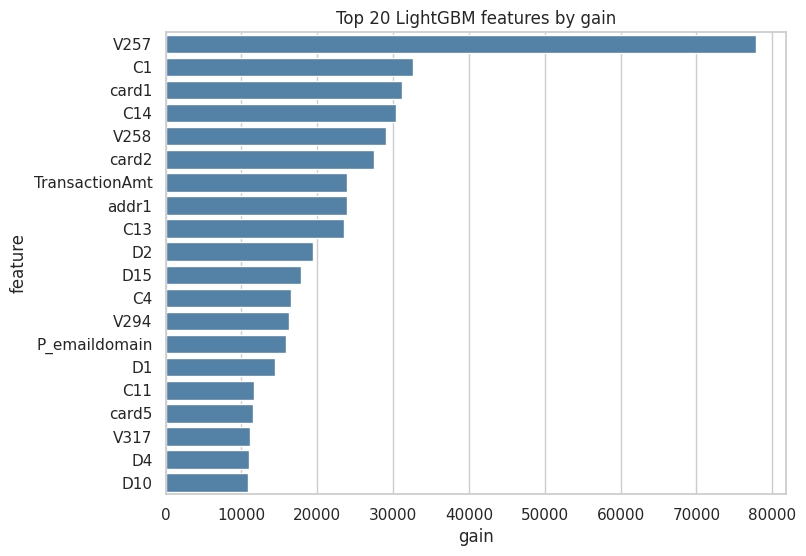

In [10]:
def top_feature_importances(model, features, top_n):
    """The top_n features by total split gain."""
    gains = model.booster_.feature_importance(importance_type='gain')
    importances = pd.DataFrame({'feature': features, 'gain': gains})
    return importances.sort_values('gain', ascending=False).head(top_n)


top_importances = top_feature_importances(lgbm_model, feature_columns, TOP_N_IMPORTANCES)
plt.figure(figsize=(8, 6))
sns.barplot(x='gain', y='feature', data=top_importances, color='steelblue')
plt.title(f'Top {TOP_N_IMPORTANCES} LightGBM features by gain')
plt.show()

### Retrain on all training data and write the submission

The final model trains on all of train, including the validation slice, since that's the data closest in time to test. It uses the number of trees early stopping chose.

In [11]:
final_model = build_lightgbm(best_rounds)
final_model.fit(train[feature_columns], train[TARGET])
test_fraud_probabilities = final_model.predict_proba(test[feature_columns])[:, 1]

submission = pd.DataFrame({ID_COLUMN: test[ID_COLUMN], TARGET: test_fraud_probabilities})
submission.to_csv(SUBMISSION_PATH, index=False)

# The submission must have one row per test transaction, in the same order as Kaggle's sample file
sample_submission = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))
same_ids = np.array_equal(submission[ID_COLUMN].to_numpy(), sample_submission[ID_COLUMN].to_numpy())
print(f'wrote {SUBMISSION_PATH}: {len(submission):,} rows; matches sample_submission IDs: {same_ids}')
print(submission.head().to_string(index=False))

wrote submission.csv: 506,691 rows; matches sample_submission IDs: True
 TransactionID  isFraud
       3663549 0.002536
       3663550 0.002857
       3663551 0.003574
       3663552 0.001870
       3663553 0.003108


### What the baselines show

- Logistic regression on 17 columns: validation AUC of **0.7787**.
- LightGBM on all columns: validation AUC of **0.9227** at **277** trees.
- Top features by gain: **V257** is far ahead of everything else, with roughly twice the gain of the next feature. It's followed by **C1, card1, C14, V258, card2, TransactionAmt and addr1**. The V columns are anonymized, so I can't say what V257 measures. Card and address columns (card1, card2, card5, addr1) and the time-delta D columns (D1, D2, D4, D10, D15) show up throughout the top 20, which supports next week's plan to group transactions by card, address and D1 into an approximate customer ID.

**Next week:** reduce the redundant V columns, add frequency encoding for high-cardinality columns, and try grouping transactions by card and address to approximate a customer ID.